In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# 데이터 읽기
df = pd.read_csv('./data/i.csv', encoding='euc-kr')

In [2]:
# 입항 기록만 추출
data = df[df["입출"].astype(str).str.strip() == "입항"].copy()

# 날짜 및 승객 수 변환
data["입항일시"] = pd.to_datetime(
    data["입항일시"],
    errors="coerce"
)

data["승객"] = pd.to_numeric(
    data["승객"],
    errors="coerce"
)

# 입항일시가 없는 데이터 제외
data = data.dropna(subset=["입항일시"]).copy()

# 분석용 파생 변수 생성
data["연도"] = data["입항일시"].dt.year
data["월"] = data["입항일시"].dt.month
data["요일번호"] = data["입항일시"].dt.dayofweek
data["요일"] = data["요일번호"].map({
    0: "월요일",
    1: "화요일",
    2: "수요일",
    3: "목요일",
    4: "금요일",
    5: "토요일",
    6: "일요일"
})
data["시간"] = data["입항일시"].dt.hour

# 월과 요일 표시용 순서
요일순서 = [
    "월요일", "화요일", "수요일", "목요일",
    "금요일", "토요일", "일요일"
]

월이름 = {
    i: f"{i}월" for i in range(1, 13)
}

print("\n분석 대상 입항 건수:", len(data))
print("입항일시 결측 제거 후 승객 수 결측 건수:",
      data["승객"].isna().sum())


분석 대상 입항 건수: 1518
입항일시 결측 제거 후 승객 수 결측 건수: 2



1. 연도별 입항 횟수 및 승객 수
      입항횟수       승객수  승객수_결측제외건수   평균승객수  전년대비_입항증감률(%)  전년대비_승객증감률(%)
연도                                                                    
2013   106  199170.0         106  1879.0            NaN            NaN
2014   104  240251.0         104  2310.1           -1.9           20.6
2015    64  161654.0          64  2525.8          -38.5          -32.7
2016   205  560887.0         205  2736.0          220.3          247.0
2017    89  158128.0          89  1776.7          -56.6          -71.8
2018    80  128795.0          80  1609.9          -10.1          -18.6
2019   107  189053.0         107  1766.9           33.7           46.8
2023   105  151351.0         105  1441.4           -1.9          -19.9
2024   114  152892.0         114  1341.2            8.6            1.0
2025   205  258697.0         203  1274.4           79.8           69.2
2026   339  571841.0         339  1686.8           65.4          121.0


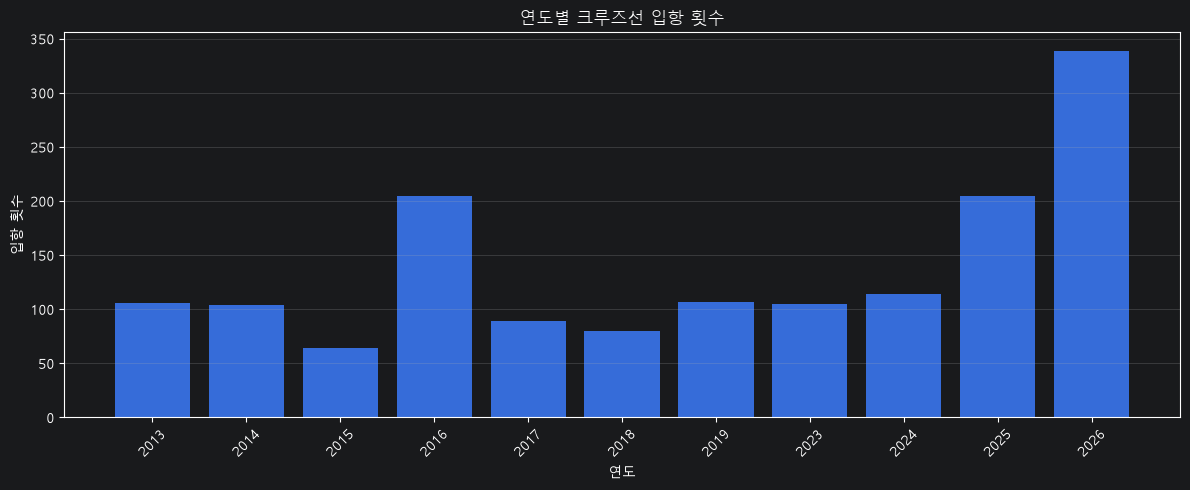

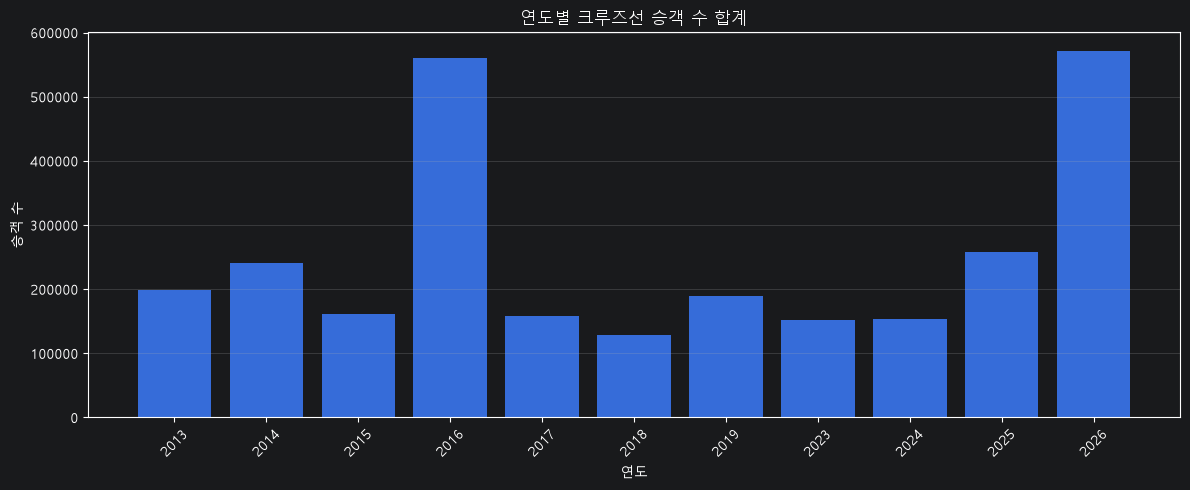

In [6]:
연도별 = data.groupby("연도").agg(
    입항횟수=("입항일시", "size"),
    승객수=("승객", "sum"),
    승객수_결측제외건수=("승객", "count")
)

연도별["평균승객수"] = (
    연도별["승객수"] / 연도별["승객수_결측제외건수"]
)

연도별["전년대비_입항증감률(%)"] = (
    연도별["입항횟수"].pct_change() * 100
)

연도별["전년대비_승객증감률(%)"] = (
    연도별["승객수"].pct_change() * 100
)

print("\n" + "=" * 60)
print("1. 연도별 입항 횟수 및 승객 수")
print("=" * 60)
print(연도별.round(1).to_string())


# 그래프 1: 연도별 입항 횟수
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(연도별.index.astype(str), 연도별["입항횟수"])
ax.set_title("연도별 크루즈선 입항 횟수")
ax.set_xlabel("연도")
ax.set_ylabel("입항 횟수")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# 그래프 2: 연도별 승객 수
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(연도별.index.astype(str), 연도별["승객수"])
ax.set_title("연도별 크루즈선 승객 수 합계")
ax.set_xlabel("연도")
ax.set_ylabel("승객 수")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()




2. 월별 입항 횟수 및 승객 수
     입항횟수       승객수  승객수_결측제외건수   평균승객수
월                                      
1월     56   94713.0          56  1691.3
2월     51  113904.0          51  2233.4
3월    135  190692.0         134  1423.1
4월    219  285971.0         219  1305.8
5월    207  349666.0         207  1689.2
6월    158  324960.0         158  2056.7
7월    125  293863.0         125  2350.9
8월    143  324633.0         143  2270.2
9월    160  324031.0         160  2025.2
10월   151  271453.0         151  1797.7
11월    69  137105.0          69  1987.0
12월    44   61728.0          43  1435.5


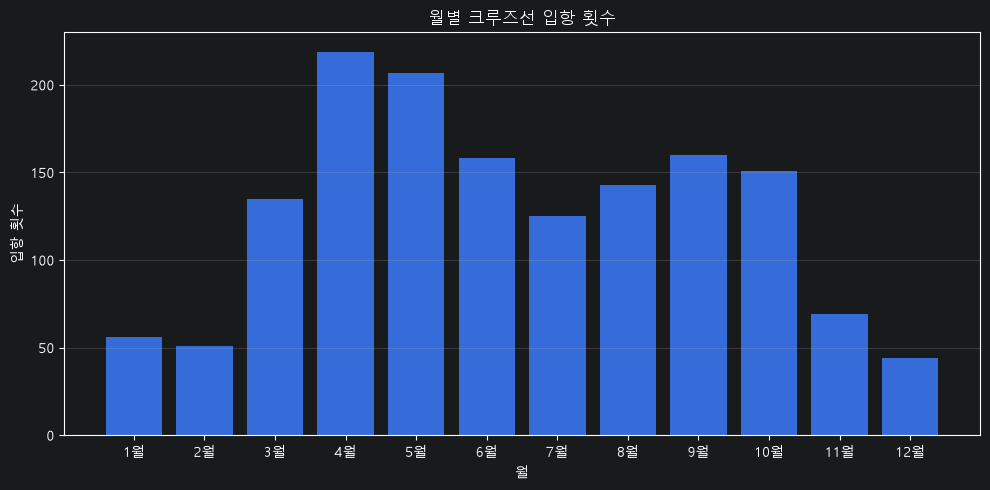

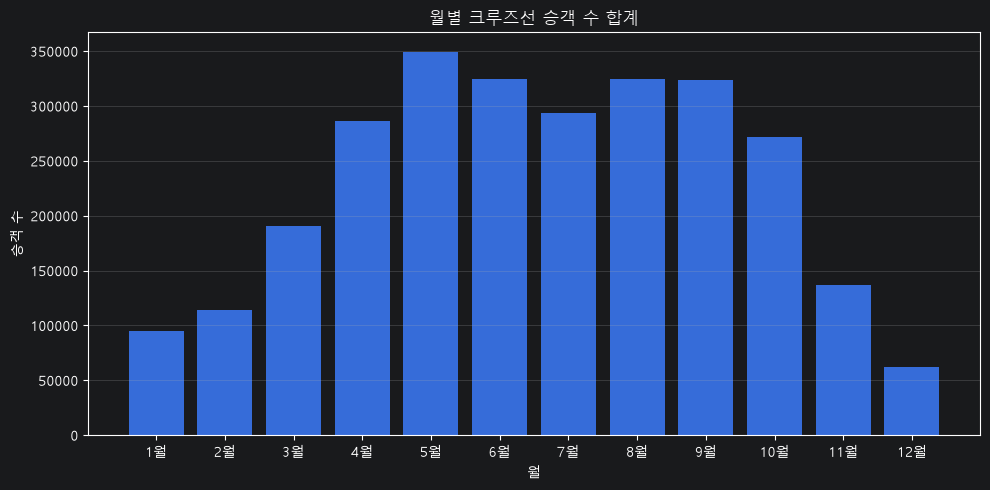

In [7]:
월별 = data.groupby("월").agg(
    입항횟수=("입항일시", "size"),
    승객수=("승객", "sum"),
    승객수_결측제외건수=("승객", "count")
).reindex(range(1, 13), fill_value=0)

월별["평균승객수"] = (
    월별["승객수"] /
    월별["승객수_결측제외건수"].replace(0, pd.NA)
)

월별.index = 월별.index.map(월이름)

print("\n" + "=" * 60)
print("2. 월별 입항 횟수 및 승객 수")
print("=" * 60)
print(월별.round(1).to_string())



# 그래프 3: 월별 입항 횟수
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(월별.index, 월별["입항횟수"])
ax.set_title("월별 크루즈선 입항 횟수")
ax.set_xlabel("월")
ax.set_ylabel("입항 횟수")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# 그래프 4: 월별 승객 수
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(월별.index, 월별["승객수"])
ax.set_title("월별 크루즈선 승객 수 합계")
ax.set_xlabel("월")
ax.set_ylabel("승객 수")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



2013~2025년 월별 입항 횟수 및 승객 수
     입항횟수       승객수  승객수_결측제외건수   평균승객수
월                                      
1월     38   69857.0          38  1838.3
2월     31   75536.0          31  2436.6
3월     85  132472.0          84  1577.0
4월    173  239610.0         173  1385.0
5월    161  275734.0         161  1712.6
6월    117  244300.0         117  2088.0
7월     92  214212.0          92  2328.4
8월    116  265287.0         116  2287.0
9월    122  248372.0         122  2035.8
10월   131  236665.0         131  1806.6
11월    69  137105.0          69  1987.0
12월    44   61728.0          43  1435.5


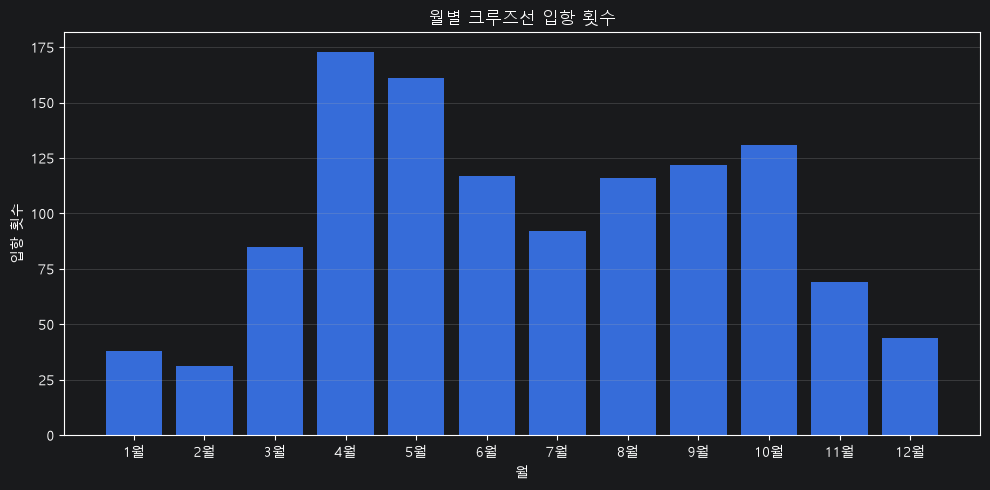

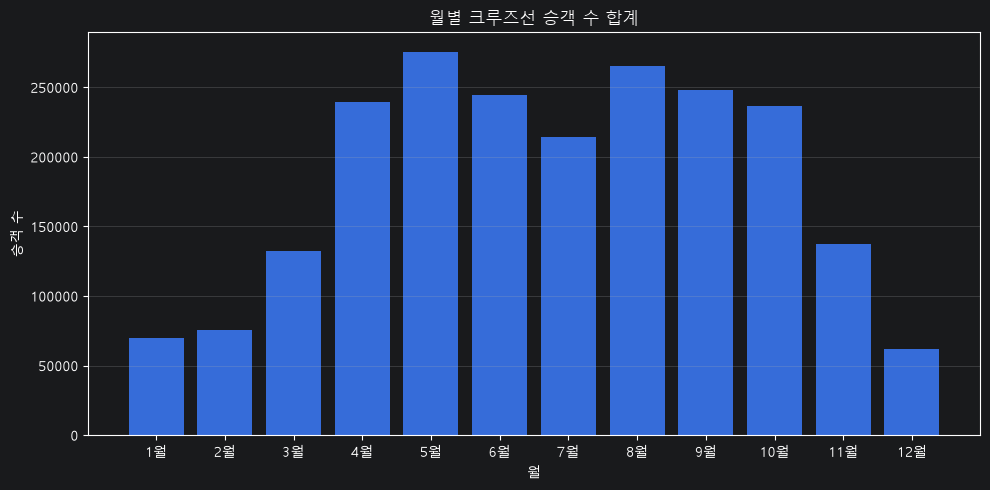

In [9]:
# 월별 분석 전용 데이터: 2026년 제외
data_month = data[data["연도"] != 2026].copy()

월별 = data_month.groupby("월").agg(
    입항횟수=("입항일시", "size"),
    승객수=("승객", "sum"),
    승객수_결측제외건수=("승객", "count")
).reindex(range(1, 13), fill_value=0)

월별["평균승객수"] = (
    월별["승객수"] /
    월별["승객수_결측제외건수"].replace(0, pd.NA)
)

월별.index = 월별.index.map(월이름)

print("\n2013~2025년 월별 입항 횟수 및 승객 수")
print(월별.round(1).to_string())

# 그래프 3: 월별 입항 횟수
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(월별.index, 월별["입항횟수"])
ax.set_title("월별 크루즈선 입항 횟수")
ax.set_xlabel("월")
ax.set_ylabel("입항 횟수")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# 그래프 4: 월별 승객 수
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(월별.index, 월별["승객수"])
ax.set_title("월별 크루즈선 승객 수 합계")
ax.set_xlabel("월")
ax.set_ylabel("승객 수")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



2013~2025년 요일별 입항 횟수 및 승객 수
     입항횟수       승객수  승객수_결측제외건수  전체비중(%)   평균승객수
요일                                              
월요일   175  311737.0         175     14.8  1781.4
화요일   164  309107.0         164     13.9  1884.8
수요일   176  332211.0         176     14.9  1887.6
목요일   158  324016.0         157     13.4  2063.8
금요일   162  312784.0         162     13.7  1930.8
토요일   147  275182.0         146     12.5  1884.8
일요일   197  335841.0         197     16.7  1704.8


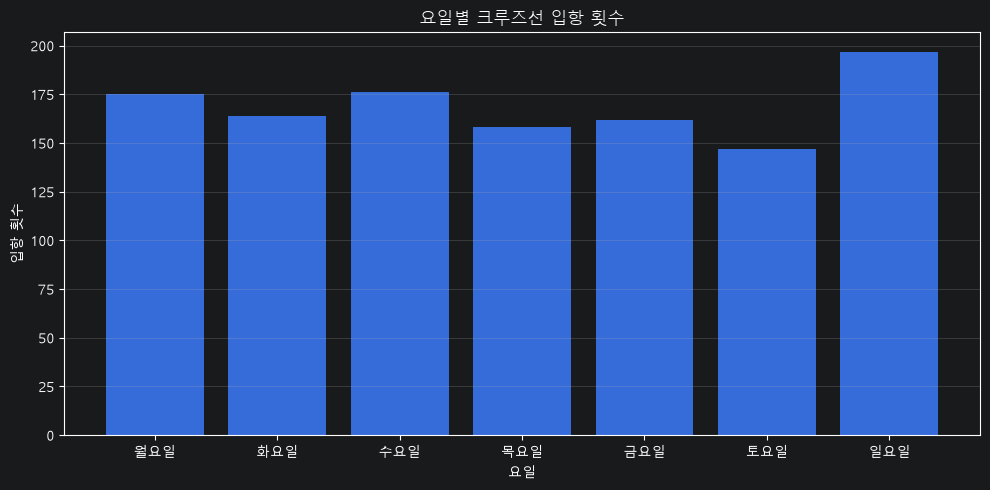

In [10]:
# 요일별 분석 전용 데이터: 2026년 제외
data_weekday = data[data["연도"] != 2026].copy()

요일별 = data_weekday.groupby("요일").agg(
    입항횟수=("입항일시", "size"),
    승객수=("승객", "sum"),
    승객수_결측제외건수=("승객", "count")
).reindex(요일순서, fill_value=0)

요일별["전체비중(%)"] = (
    요일별["입항횟수"] / 요일별["입항횟수"].sum() * 100
)

요일별["평균승객수"] = (
    요일별["승객수"] /
    요일별["승객수_결측제외건수"].replace(0, pd.NA)
)

print("\n2013~2025년 요일별 입항 횟수 및 승객 수")
print(요일별.round(1).to_string())

# 그래프 5: 요일별 입항 횟수
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(요일별.index, 요일별["입항횟수"])
ax.set_title("요일별 크루즈선 입항 횟수")
ax.set_xlabel("요일")
ax.set_ylabel("입항 횟수")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



4. 시간대별 입항 횟수 및 승객 수 (2013~2025년)
    입항횟수       승객수  승객수_결측제외건수  전체비중(%)        평균승객수
시간                                                  
0      3    8102.0           3     0.25  2700.666667
1      1    4347.0           1     0.08       4347.0
2      1    1793.0           1     0.08       1793.0
3      1      85.0           1     0.08         85.0
4      3    3133.0           3     0.25  1044.333333
5     50   84508.0          50     4.24      1690.16
6    296  616293.0         296    25.11  2082.070946
7    309  570579.0         309    26.21  1846.533981
8    170  264590.0         170    14.42  1556.411765
9     98  188959.0          98     8.31  1928.153061
10    48   79256.0          47     4.07  1686.297872
11    63  107622.0          63     5.34  1708.285714
12    53  104755.0          53     4.50  1976.509434
13    41   97544.0          41     3.48  2379.121951
14    19   34484.0          18     1.61  1915.777778
15     5   10828.0           5     0.42       2165.6
16     8   

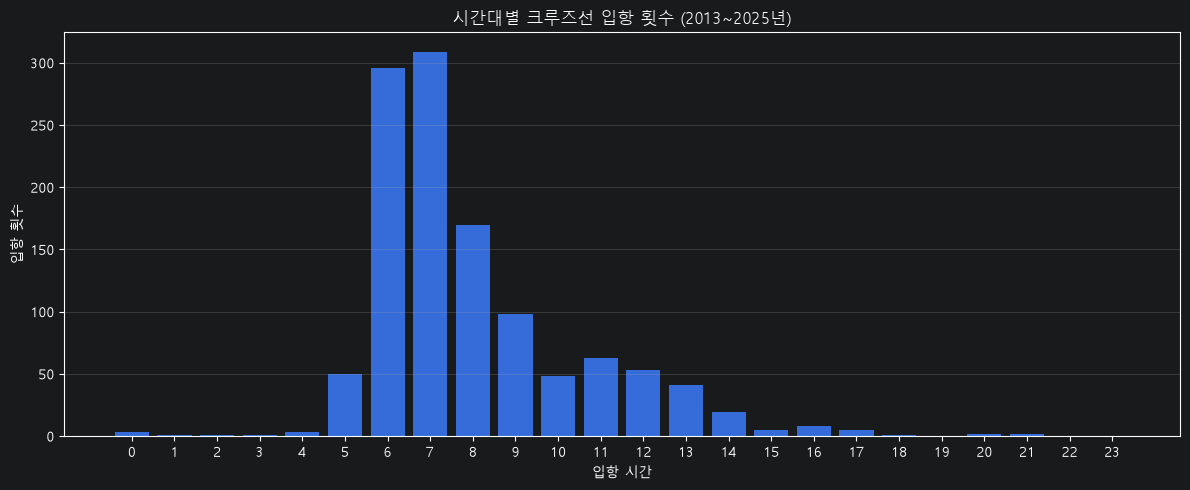


시간 구간별 입항 집중도 (2013~2025년)
        입항횟수  비중(%)
시간                 
00~05시    59   5.00
06~11시   984  83.46
12~17시   131  11.11
18~23시     5   0.42


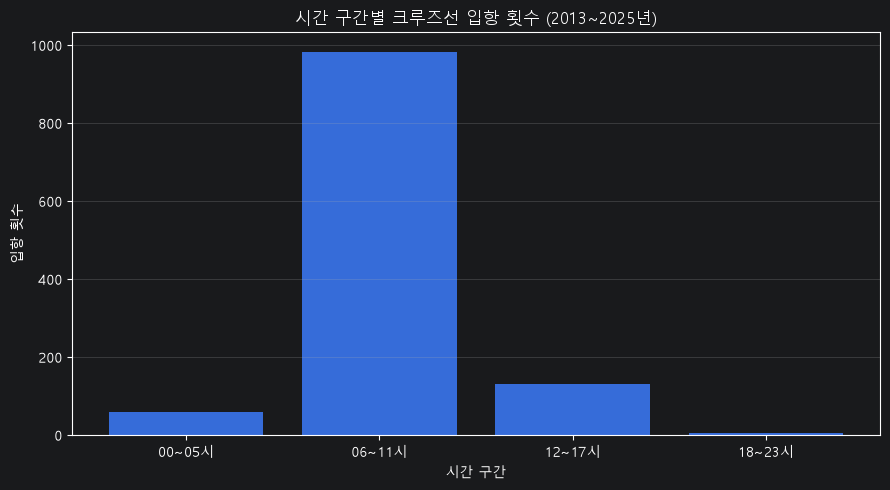

In [11]:

# 2026년 제외
data_time = data[data["연도"] != 2026].copy()

# 시간대별 집계
시간대별 = data_time.groupby("시간").agg(
    입항횟수=("입항일시", "size"),
    승객수=("승객", "sum"),
    승객수_결측제외건수=("승객", "count")
).reindex(range(24), fill_value=0)

# 시간대별 입항 비중
시간대별["전체비중(%)"] = (
    시간대별["입항횟수"]
    / 시간대별["입항횟수"].sum()
    * 100
)

# 입항 1회당 평균 승객 수
시간대별["평균승객수"] = (
    시간대별["승객수"]
    / 시간대별["승객수_결측제외건수"].replace(0, pd.NA)
)

print("\n" + "=" * 60)
print("4. 시간대별 입항 횟수 및 승객 수 (2013~2025년)")
print("=" * 60)

print(시간대별.round(2).to_string())

상위시간대 = 시간대별.sort_values(
    "입항횟수",
    ascending=False
).head(5)

print("\n입항 횟수가 많은 상위 5개 시간대 (2013~2025년)")
print(상위시간대.round(2).to_string())

fig, ax = plt.subplots(figsize=(12, 5))

ax.bar(
    시간대별.index,
    시간대별["입항횟수"]
)

ax.set_title("시간대별 크루즈선 입항 횟수 (2013~2025년)")
ax.set_xlabel("입항 시간")
ax.set_ylabel("입항 횟수")
ax.set_xticks(range(24))
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

시간구간 = pd.cut(
    data_time["시간"],
    bins=[-1, 5, 11, 17, 23],
    labels=[
        "00~05시",
        "06~11시",
        "12~17시",
        "18~23시"
    ]
)

시간구간별 = 시간구간.value_counts(
    sort=False
).to_frame("입항횟수")

시간구간별["비중(%)"] = (
    시간구간별["입항횟수"]
    / 시간구간별["입항횟수"].sum()
    * 100
)

print("\n시간 구간별 입항 집중도 (2013~2025년)")
print(시간구간별.round(2).to_string())

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    시간구간별.index.astype(str),
    시간구간별["입항횟수"]
)

ax.set_title("시간 구간별 크루즈선 입항 횟수 (2013~2025년)")
ax.set_xlabel("시간 구간")
ax.set_ylabel("입항 횟수")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

최다시간 = 시간대별["입항횟수"].idxmax()



월·요일별 크루즈선 입항 횟수 (2013~2025년)
요일     월요일  화요일  수요일  목요일  금요일  토요일  일요일  월별_합계
월                                              
1월       5    5    4   10    3    4    7     38
2월       8    2    7    5    4    1    4     31
3월      12   10    8   11   18    9   17     85
4월      22   31   29   21   22   21   27    173
5월      20   27   22   27   27   19   19    161
6월      15   16   23   15   11   16   21    117
7월      13   10   15    9   11   14   20     92
8월      18   13   18   16   12   16   23    116
9월      17   12   17   13   25   16   22    122
10월     20   18   16   18   19   19   21    131
11월     13   11   10    9    7    7   12     69
12월     12    9    7    4    3    5    4     44
전체_합계  175  164  176  158  162  147  197   1179

월별 입항 횟수가 가장 많은 요일
  월        최다입항요일  입항횟수
 1월           목요일    10
 2월           월요일     8
 3월           금요일    18
 4월           화요일    31
 5월 화요일, 목요일, 금요일    27
 6월           수요일    23
 7월           일요일    20
 8월           일요일    23
 9월          

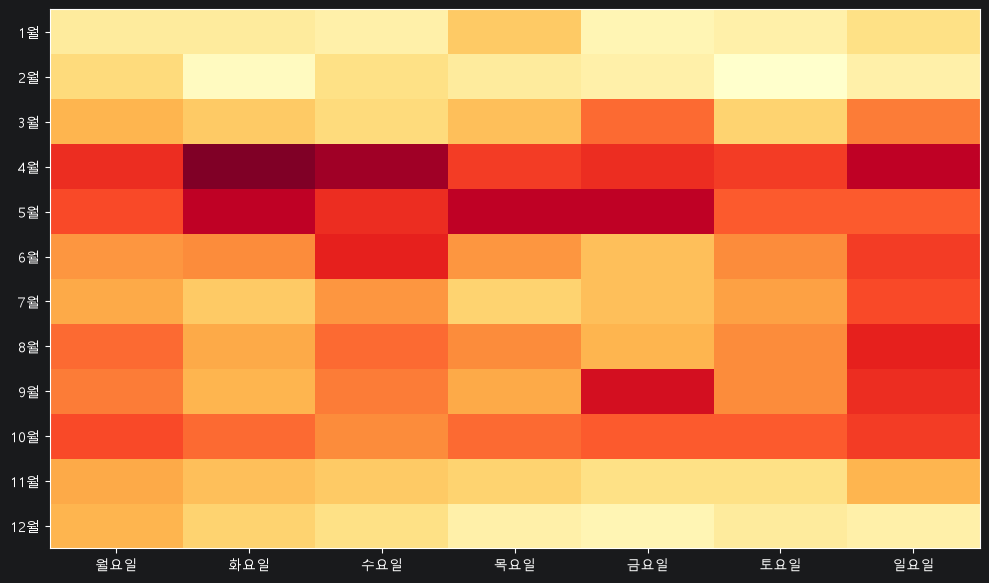

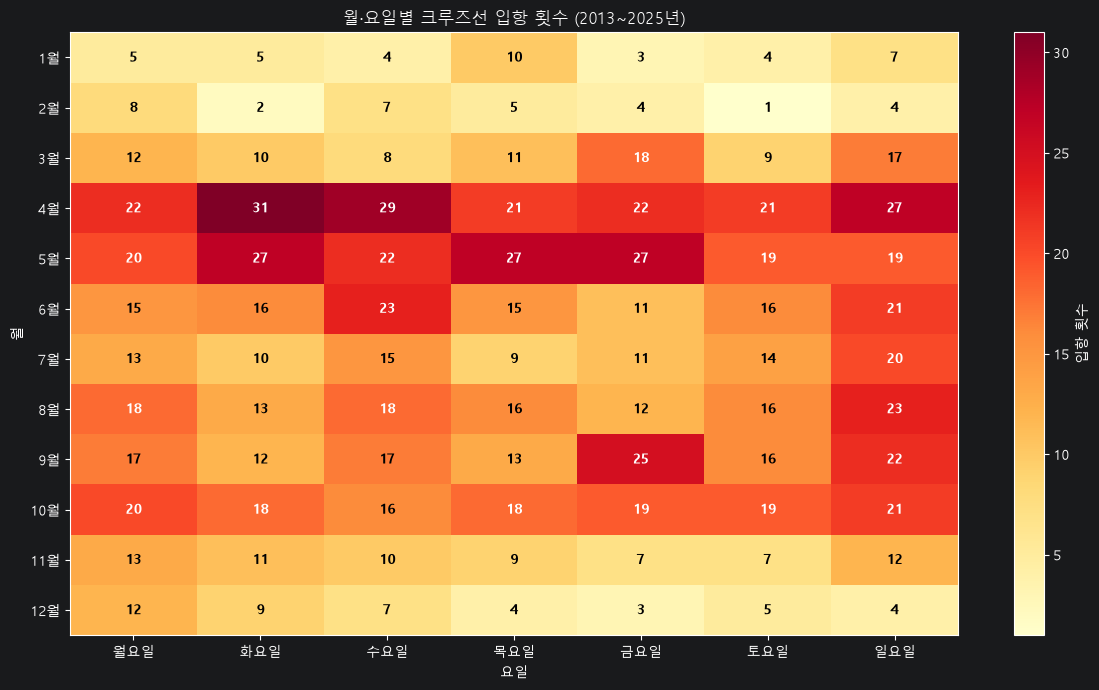

In [13]:
# =========================================================
# 6. 월·요일별 입항 패턴 비교 분석
#    (2026년 제외: 2013~2025년)
# =========================================================

# 2026년 제외
data_pattern = data[data["연도"] != 2026].copy()

요일순서 = [
    "월요일", "화요일", "수요일", "목요일",
    "금요일", "토요일", "일요일"
]

월이름 = {
    i: f"{i}월" for i in range(1, 13)
}


# =========================================================
# 6-1. 월·요일별 입항 횟수 교차표
# =========================================================

월요일_교차표 = pd.crosstab(
    data_pattern["월"],
    data_pattern["요일"]
).reindex(
    index=range(1, 13),
    columns=요일순서,
    fill_value=0
)

월요일_교차표.index = 월요일_교차표.index.map(월이름)

# 월별 전체 입항 횟수
월요일_교차표["월별_합계"] = 월요일_교차표.sum(axis=1)

# 요일별 전체 입항 횟수
월요일_교차표.loc["전체_합계"] = 월요일_교차표.sum(axis=0)

print("\n" + "=" * 60)
print("월·요일별 크루즈선 입항 횟수 (2013~2025년)")
print("=" * 60)

print(월요일_교차표.to_string())


# =========================================================
# 6-2. 월별 입항 횟수가 가장 많은 요일
# =========================================================

# 합계 행과 합계 열을 제외한 교차표
교차표_순수 = pd.crosstab(
    data_pattern["월"],
    data_pattern["요일"]
).reindex(
    index=range(1, 13),
    columns=요일순서,
    fill_value=0
)

최다요일_결과 = []

for 월 in range(1, 13):

    요일별_횟수 = 교차표_순수.loc[월]

    최대횟수 = 요일별_횟수.max()

    최다요일 = 요일별_횟수[
        요일별_횟수 == 최대횟수
    ].index.tolist()

    최다요일_결과.append({
        "월": f"{월}월",
        "최다입항요일": ", ".join(최다요일),
        "입항횟수": 최대횟수
    })

최다요일_df = pd.DataFrame(최다요일_결과)

print("\n월별 입항 횟수가 가장 많은 요일")
print(최다요일_df.to_string(index=False))



# =========================================================
# 6-3. 월·요일별 입항 횟수 히트맵
# =========================================================

fig, ax = plt.subplots(figsize=(12, 7))

im = ax.imshow(
    교차표_순수.values,
    aspect="auto",
    cmap="YlOrRd"
)

ax.set_xticks(range(len(요일순서)))
ax.set_xticklabels(요일순서)

ax.set_yticks(range(12))
ax.set_yticklabels(
    [f"{월}월" for 월 in range(1, 13)]
)

ax.set


# =========================================================
# 월·요일별 입항 횟수 히트맵 (셀 내부 숫자 표시)
# =========================================================

fig, ax = plt.subplots(figsize=(12, 7))

im = ax.imshow(
    교차표_순수.values,
    aspect="auto",
    cmap="YlOrRd"
)

# x축: 요일
ax.set_xticks(range(len(요일순서)))
ax.set_xticklabels(요일순서)

# y축: 월
ax.set_yticks(range(12))
ax.set_yticklabels(
    [f"{월}월" for 월 in range(1, 13)]
)

ax.set_title(
    "월·요일별 크루즈선 입항 횟수 (2013~2025년)"
)
ax.set_xlabel("요일")
ax.set_ylabel("월")

# 각 셀 중앙에 입항 횟수 표시
최대값 = 교차표_순수.values.max()

for i in range(교차표_순수.shape[0]):
    for j in range(교차표_순수.shape[1]):

        값 = 교차표_순수.iloc[i, j]

        # 배경색에 따라 글자색 변경
        글자색 = "white" if 값 > 최대값 * 0.55 else "black"

        ax.text(
            j,
            i,
            f"{값}",
            ha="center",
            va="center",
            color=글자색,
            fontsize=10,
            fontweight="bold"
        )

# 색상 범례
fig.colorbar(
    im,
    ax=ax,
    label="입항 횟수"
)

plt.tight_layout()
plt.show()